1. Linear Regression (Simple & Multiple Linear Regression)Lý thuyết & Nguyên lý: Mô hình dự đoán đầu ra bằng cách khớp một siêu phẳng tuyến tính $y = X\beta + \epsilon$12. Phương pháp Bình phương tối thiểu (OLS) tìm tập trọng số $\beta$ sao cho tối thiểu hóa Sai số bình phương trung bình (MSE)13: $$\text{MSE} = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$ Mô hình dựa trên giả định về tính tuyến tính, độc lập của sai số, homoscedasticity (phương sai sai số không đổi), và sai số tuân theo phân phối chuẩn1.

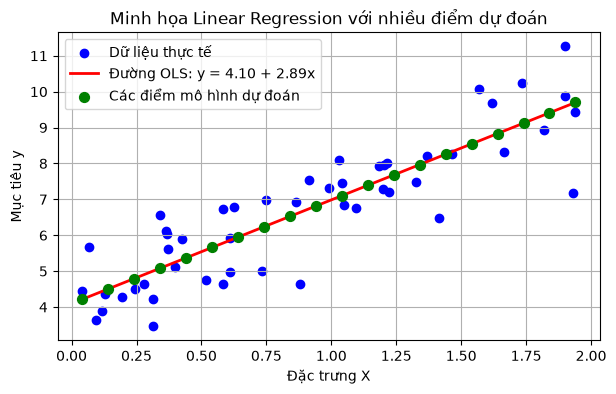

In [8]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression

# Tạo dữ liệu giả lập
np.random.seed(42)
X = 2 * np.random.rand(50, 1)
y = 4 + 3 * X + np.random.randn(50, 1)

# Huấn luyện mô hình Linear Regression
model = LinearRegression()
model.fit(X, y)

# Tạo ra nhiều điểm X_new hơn (ví dụ 20 điểm trải đều từ min đến max của X)
X_new = np.linspace(X.min(), X.max(), 20).reshape(-1, 1)
y_predict = model.predict(X_new)

# Vẽ đồ thị
plt.figure(figsize=(7, 4))

# 1. Vẽ dữ liệu thực tế
plt.scatter(X, y, color='blue', label='Dữ liệu thực tế')

# 2. Vẽ đường thẳng OLS
plt.plot(
    X_new,
    y_predict,
    color='red',
    linewidth=2,
    label=f'Đường OLS: y = {model.intercept_[0]:.2f} + {model.coef_[0][0]:.2f}x',
)

# 3. Vẽ nhiều điểm dự đoán của mô hình trên đường OLS
plt.scatter(
    X_new,
    y_predict,
    color='green',
    s=50,
    zorder=5,
    label='Các điểm mô hình dự đoán',
)

plt.title('Minh họa Linear Regression với nhiều điểm dự đoán')
plt.xlabel('Đặc trưng X')
plt.ylabel('Mục tiêu y')
plt.legend()
plt.grid(True)
plt.show()

# Tổng Quan Về Mô Hình Linear Regression (Hồi Quy Tuyến Tính)

Linear Regression là một trong những thuật toán Machine Learning cơ bản và quan trọng nhất, được sử dụng để dự đoán giá trị liên tục dựa trên mối quan hệ tuyến tính giữa biến đầu vào (X) và biến mục tiêu (y).

---

## 1. Ưu Điểm (Pros)

- **Đơn giản và dễ giải thích:** Cấu trúc toán học rõ ràng ($y = ax + b$). Các hệ số $\beta$ phản ánh trực tiếp mức độ và hướng ảnh hưởng của từng đặc trưng lên kết quả dự đoán.

- **Tốc độ tính toán nhanh:** Phương pháp Bình phương Tối thiểu (OLS) có thể tính toán trọng số cực kỳ nhanh, tiêu tốn rất ít tài nguyên phần cứng.

- **Hoạt động tốt trên dữ liệu tuyến tính:** Nếu mối quan hệ giữa biến đầu vào và biến mục tiêu thực sự có dạng tuyến tính, mô hình mang lại hiệu năng rất cao.
- **Ít bị Overfitting:** Do bản chất là một mô hình đơn giản, nó ít bị học thuộc lòng các nhiễu (noise) nhỏ trong tập dữ liệu huấn luyện so với các mô hình phức tạp.

- **Làm Benchmark hiệu quả:** Thường được dùng làm mô hình cơ sở (baseline model) để so sánh hiệu năng với các thuật toán phức tạp hơn như Random Forest, XGBoost hay Neural Networks.

---

## 2. Nhược Điểm (Cons)

- **Giả định tính tuyến tính cứng nhắc:** Thực tế dữ liệu thường có quan hệ phi tuyến (đường cong, cấu trúc phức tạp). Khi đó mô hình dễ bị **Underfitting** (dự đoán kém).

- **Rất nhạy cảm với dữ liệu ngoại lai (Outliers):** Phương pháp OLS tối thiểu hóa tổng bình phương sai số, nên chỉ cần một vài điểm dữ liệu lệch xa có thể kéo lệch toàn bộ đường/siêu phẳng hồi quy.

- **Bị ảnh hưởng bởi hiện tượng Đa cộng tuyến (Multicollinearity):** Khi các biến đặc trưng đầu vào có mối tương quan mạnh với nhau, việc ước lượng các hệ số trọng số sẽ trở nên kém ổn định và khó giải thích.

- **Phụ thuộc vào các giả định thống kê:**
  - *Homoscedasticity:* Phương sai của sai số phải không đổi trên toàn dải dữ liệu.
  - *Independence:* Các sai số giữa các quan sát độc lập với nhau.
  - *Normality:* Sai số tuân theo phân phối chuẩn.

---

## 3. Các Trường Hợp Sử Dụng Thực Tế (Use Cases)

| Lĩnh vực | Ứng dụng cụ thể | Đặc trưng đầu vào ($X$) | Mục tiêu dự đoán ($y$) |
| :--- | :--- | :--- | :--- |
| **Bất động sản** | Định giá nhà ở | Diện tích, số phòng, vị trí, khoảng cách đến trung tâm | Giá bán căn nhà |
| **Tài chính & Kinh doanh** | Dự báo doanh thu | Chi phí Marketing, số lượng nhân sự, mùa vụ | Doanh số bán hàng |
| **Bán lẻ & Thương mại** | Phân tích độ nhạy giá | Mức giá niêm yết, tỷ lệ giảm giá | Số lượng sản phẩm bán ra |
| **Giáo dục & Y tế** | Ước tính chỉ số | Số giờ học/luyện tập, chế độ dinh dưỡng | Điểm số kỳ thi / Chỉ số sức khỏe |
| **Vận tải & Logistics** | Dự đoán thời gian | Quãng đường di chuyển, số điểm dừng, khối lượng hàng | Thời gian giao hàng dự kiến |

---



In [9]:
import numpy as np
from sklearn.linear_model import LinearRegression

# 1. Khởi tạo dữ liệu giả lập
np.random.seed(42)
X = 2 * np.random.rand(50, 1)
y = 4 + 3 * X + np.random.randn(50, 1)

# 2. Khởi tạo và huấn luyện mô hình OLS
model = LinearRegression()
model.fit(X, y)

# 3. Dự đoán với dữ liệu mới
X_new = np.array([[1.5], [3.0]])
y_pred = model.predict(X_new)

print(f"Hệ số chặn (Intercept): {model.intercept_[0]:.2f}")
print(f"Hệ số góc (Slope): {model.coef_[0][0]:.2f}")
print("Dự đoán tại X_new:\n", y_pred)

Hệ số chặn (Intercept): 4.10
Hệ số góc (Slope): 2.89
Dự đoán tại X_new:
 [[ 8.42911378]
 [12.76153828]]
